# Signature and stamp localization

## What you will build

**Recipe 78 · Level 3 (Intermediate) · `Noul` + `Box`**

Build a document-mark locator that returns one proposed crop, a confident absence, or an explicit [review](../../docs/glossary.md#review) — a deferral to a person. Two `Noul` propositions check visible presence and uniqueness. Python requests a `Box` only after those checks pass, validates coordinates, and simulates a crop.

The forms below are authored synthetic drawings. Names are fictional and signatures are meaningless mathematical scribbles. Locating ink establishes neither identity nor authenticity nor approval authority. No approvals are issued and no document is modified.

A Box always supplies coordinates even when the target is absent (S10), which makes a separate presence check essential. Images and Box are experimental; the live configuration pins `jev-1.14.0` with images enabled (S09–S12).

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S10: [Box](https://docs.typesafe.ai/primitives/box)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## Setup and run mode

The default [replay backend](../../docs/backends.md) reads hand-authored answers keyed by the image bytes and the exact questions. This synthetic run is a pipeline check, not a Jev quality measurement. The sample contains 12 validation documents, 12 held-out test documents and two unscored demonstrations. Each source image is an upright 600 × 760 PNG generated by `build_fixtures.py`.

A logical request budget stops this run at 52 calls, at most two per document. The live backend separately limits HTTP attempts, including retries. Each example is observed once and reused for displays and evaluation.

In [1]:
import json
from pathlib import Path

from IPython.display import display

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.style import apply_style, run_header, show_answer

apply_style()
root = Path(".")
helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
budget = helpers.RequestBudget(52)
observations = {}
offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
selection = " (a selection step, not a reported result)"
run_header(78, "Signature and stamp localization", backend=backend, n_examples=24)

Recipe 78: Signature and stamp localization
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Inference receives the document pixels under an opaque content-derived reference and a legitimate request for either a handwritten signature or an approval stamp containing “APPROVED.” Filename, split, drawing case, gold bounds and fabricated probabilities stay outside the request.

The first form uses a rotated ink mark on an upright page. Printed names and signature guide lines are distractors, not part of the requested crop. `assets/README.md` describes the authoring process and limitations.

{'document': 'image:sha256:b949841306948d16e121d7907d845b84a4f33268f0eaca3408496c849340a669', 'requested_mark': 'the handwritten signature mark, excluding the printed name and blank line'}
Asset count: 1 | dimensions: (600, 760)


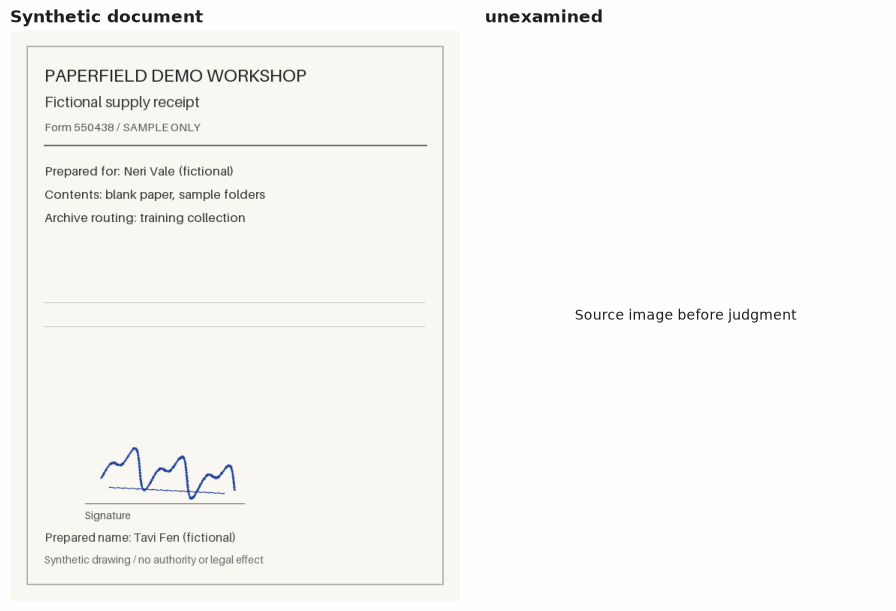

In [2]:
demo = next(e for e in examples if e.id == "d01")
state, assets = helpers.request_data(demo.fields, root)
print(state)
print("Asset count:", len(assets), "| dimensions:", helpers.dimensions(demo.fields, root))
helpers.show_location(
    demo.fields, root, helpers.Outcome("unexamined", "Source image before judgment")
)

## The questions

`Noul` represents a proposition's probability of being true; it does not supply a separate confidence field. Presence and uniqueness are independent judgments batched into one request. A later Box asks only for the visible ink envelope, excluding form labels and guide lines. It does not read a signer identity or judge whether the document has authority.

Ambiguous duplicate stamps go to review. For a partial scan, a visible target's annotation encloses its remaining ink; the hidden portion is never reconstructed.

In [3]:
for name, question in helpers.build_questions().items():
    print(name, question)
print("Dependent request:", helpers.box_questions()["mark_box"])

present Noul(instructions='The document visibly contains at least one instance of the requested mark. Judge visible marks only; printed names and empty signature lines are not handwritten signatures. A decorative seal is not an APPROVED stamp.', criteria=None)
unique Noul(instructions='Exactly one visible region matches the requested mark; there is no second equally plausible matching region. This statement is false if none is visible.', criteria=None)
Dependent request: Box(instructions='Locate the one requested mark. Enclose all of its visible ink, including the outer border of a stamp, with a tight axis-aligned rectangle. Exclude printed names, signature guide lines and surrounding form fields. For clipped marks enclose only the visible ink. Do not infer authenticity, identity or authority.')


## One answer up close

A [confidence gate](../../docs/glossary.md#confidence-gate) is Python's rule for accepting an answer only above a chosen threshold. For illustration this unscored demo uses presence 0.90 and Box confidence 0.85; validation below independently chooses the production policy. The actual typed answers appear before any aggregate metric.

Normalized edges live in [0, 1]. Python multiplies horizontal edges by image width and vertical edges by height, rounds starts down and ends up, and uses exclusive right/bottom pixel bounds. The displayed crop adds a 10% margin per side and clips at the image boundary. It is a display crop only, never uploaded as an undersized API asset.

Noul: 0.99 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Box: normalized coordinates (confidence 0.94)
  top=0.73, bottom=0.82, left=0.20, right=0.50
Provenance: synthetic
Proposed exclusive pixel bounds: (119, 553, 302, 627)


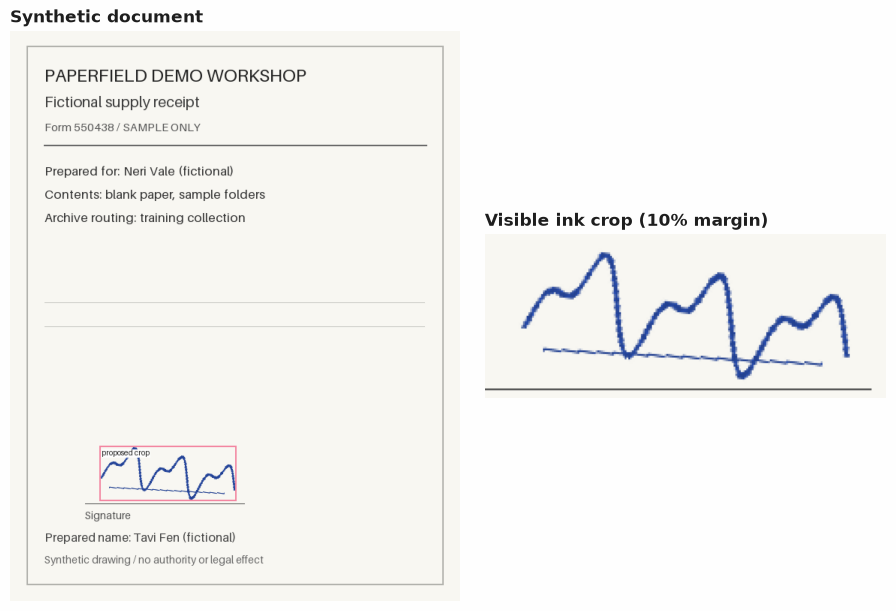

In [4]:
demo_policy = helpers.Policy(helpers.DEMO_PRESENCE, 0.85)
observations[demo.id] = helpers.observe(backend, demo.fields, root, demo_policy.presence, budget)
for answer in observations[demo.id].judgments.values():
    show_answer(answer)
if observations[demo.id].location is not None:
    show_answer(observations[demo.id].location)
else:
    print("No Box answer: first-stage gate deferred or found absence.")
demo_outcome = helpers.route(
    observations[demo.id], demo_policy, helpers.dimensions(demo.fields, root)
)
print("Proposed exclusive pixel bounds:", demo_outcome.pixels)
helpers.show_location(demo.fields, root, demo_outcome)

## Python's part

Python stops after a confident absence, uncertain presence, or failed uniqueness judgment. A contradiction between confident absence and confident uniqueness also goes to review. A passing presence gate permits one dependent Box request; missing confidence (`None`), invalid geometry or insufficient confidence prevents a crop. No retry searches for a more convenient answer.

The only simulated action kind is `simulate_crop`. A [ReviewQueue](../../docs/simulation.md) holds unresolved documents, and an [ActionLog](../../docs/simulation.md) records proposed crop coordinates with `executed=False`. Neither path changes a document or issues approval. The second demo has two equally plausible approval stamps; choosing an arbitrary one would conceal ambiguity.

Simulated crop: [{'seq': 0, 'kind': 'simulate_crop', 'payload': {'example': 'd01', 'pixels': [119, 553, 302, 627]}, 'step': None, 'answer': None, 'rule': 'presence, uniqueness, confidence and bounds gates', 'executed': False}]
Review item: [{'id': 0, 'item': {'example': 'd02'}, 'reason': 'multiple candidates or uniqueness uncertain', 'answer': None, 'step': None, 'status': 'pending', 'resolution': None}]
Approvals issued: 0
Duplicate case made Box request: False


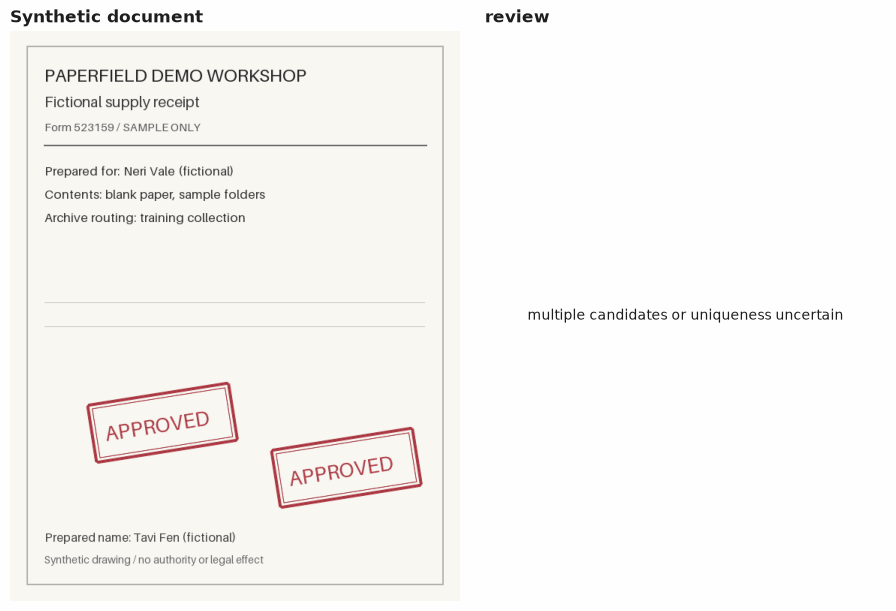

In [5]:
ambiguous_demo = next(e for e in examples if e.id == "d02")
observations[ambiguous_demo.id] = helpers.observe(
    backend, ambiguous_demo.fields, root, demo_policy.presence, budget
)
ambiguous_outcome = helpers.route(
    observations[ambiguous_demo.id], demo_policy, helpers.dimensions(ambiguous_demo.fields, root)
)
actions, reviews = helpers.empty_logs()
helpers.simulate(demo.id, demo_outcome, actions, reviews)
helpers.simulate(ambiguous_demo.id, ambiguous_outcome, actions, reviews)
print("Simulated crop:", actions.to_dicts())
print("Review item:", reviews.to_dicts())
print("Approvals issued:", len(actions.by_kind("approve_document")))
print("Duplicate case made Box request:", observations[ambiguous_demo.id].location is not None)
helpers.show_location(ambiguous_demo.fields, root, ambiguous_outcome)

## Evaluation

A [gold label](../../docs/glossary.md#gold-label) is the author-provided expected answer. Here gold marks include presence, uniqueness and an envelope of visible target ink. These annotations are separate from model state. Intersection over union (IoU) divides overlapping area by combined area; a proposed box is correct at IoU ≥ 0.50 for a unique present target. A correct absence is also a resolved answer. Ambiguous documents must remain unresolved.

Validation chooses from presence probabilities {0.80, 0.90, 0.95} and Box confidence thresholds {0.70, 0.85, 0.95}. The objective is **correct resolved answers minus twice the number of wrong crops**. Ties favor more correct resolutions, then the higher presence and Box thresholds. Every validation image is first observed with the loosest presence gate (0.80), so all candidates can reuse available Box answers. Stricter policies never need an unseen Box response.

[Coverage](../../docs/glossary.md#coverage) is the fraction actually resolved; [accuracy](../../docs/glossary.md#accuracy) is correctness among those resolved answers; [risk](../../docs/glossary.md#risk) is their error fraction. `evaluate_outcomes` receives the rule's actual accepted flags. Review is never coverage and contributes zero IoU when a unique present mark was missed. Ambiguous positives have no single gold rectangle, so we report them separately instead of picking a convenient one.

The deterministic baseline uses the **same image files**: scan only the lower half of the page, threshold blue ink for signatures or red ink for stamps, and return the largest connected component with at least 50 pixels. This fixed-layout shortcut reads no labels. It can miss upper-page or black-ink marks, select decorative seals, and choose one of duplicate stamps. Both methods use the same scoring rules.

In [6]:
if backend.mode == "live":
    raise RuntimeError(
        "Live exploration is not a reportable test. Record both stages first; see README."
    )
val_examples = [e for e in examples if e.split == "validation"]
for example in val_examples:
    observations[example.id] = helpers.observe(
        backend, example.fields, root, min(helpers.PRESENCE_CANDIDATES), budget
    )
policy, selection_rows = helpers.select_policy(
    val_examples, observations, labels, root, objective=helpers.OBJECTIVE
)
for row in selection_rows:
    values = {
        k: row[k]
        for k in (
            "presence",
            "box",
            "objective_value",
            "correct_resolutions",
            "wrong_crops",
            "reviews",
        )
    }
    print(f"Validation N={len(val_examples)}: {values}{selection}{check}")
print(f"Frozen policy: {policy}; validation N={len(val_examples)}{selection}{check}")

Validation N=12: {'presence': 0.8, 'box': 0.7, 'objective_value': 3, 'correct_resolutions': 7, 'wrong_crops': 2, 'reviews': 3} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12: {'presence': 0.8, 'box': 0.85, 'objective_value': 5, 'correct_resolutions': 7, 'wrong_crops': 1, 'reviews': 4} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12: {'presence': 0.8, 'box': 0.95, 'objective_value': 2, 'correct_resolutions': 2, 'wrong_crops': 0, 'reviews': 10} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12: {'presence': 0.9, 'box': 0.7, 'objective_value': 5, 'correct_resolutions': 7, 'wrong_crops': 1, 'reviews': 4} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12: {'presence': 0.9, 'box': 0.85, 'objective_value': 7, 'correct_resolutions': 7, 'wrong_crops': 0, 'reviews': 5} (a selection step, not a reported result) (a 

In [7]:
test_examples = [e for e in examples if e.split == "test"]
test_outcomes = {}
baseline_outcomes = {}
test_actions, test_reviews = helpers.empty_logs()
for example in test_examples:
    observations[example.id] = helpers.observe(
        backend, example.fields, root, policy.presence, budget
    )
    outcome = helpers.route(
        observations[example.id], policy, helpers.dimensions(example.fields, root)
    )
    test_outcomes[example.id] = outcome
    helpers.simulate(example.id, outcome, test_actions, test_reviews)
    baseline_outcomes[example.id] = helpers.baseline(example.fields, root)
metrics = {
    "Gated image judgments": helpers.summarize(test_examples, test_outcomes, labels),
    "Fixed ROI ink components": helpers.summarize(test_examples, baseline_outcomes, labels),
}
for name, result in metrics.items():
    print(f"Test {name}, N={len(test_examples)}{check}")
    print(
        json.dumps(
            {k: round(v, 4) if isinstance(v, float) else v for k, v in result.items()}, indent=2
        )
    )
print(f"Actual logical requests: {budget.used}; maximum: {budget.limit}{check}")
print("Test approvals issued:", len(test_actions.by_kind("approve_document")))

Test Gated image judgments, N=12 (a pipeline check, not a Jev result)
{
  "N": 12,
  "answered": 8,
  "correct_resolutions": 6,
  "reviews": 4,
  "coverage": 0.6667,
  "answered_accuracy": 0.75,
  "answered_risk": 0.25,
  "unique_present_N": 8,
  "mean_iou_with_misses": 0.4706,
  "misses": 3,
  "below_iou_target": 4,
  "absent_N": 3,
  "absent_false_positives": 1,
  "ambiguous_N": 1,
  "ambiguous_crops": 0,
  "wrong_crops": 2,
  "objective_value": 2
}
Test Fixed ROI ink components, N=12 (a pipeline check, not a Jev result)
{
  "N": 12,
  "answered": 12,
  "correct_resolutions": 6,
  "reviews": 0,
  "coverage": 1.0,
  "answered_accuracy": 0.5,
  "answered_risk": 0.5,
  "unique_present_N": 8,
  "mean_iou_with_misses": 0.52,
  "misses": 2,
  "below_iou_target": 4,
  "absent_N": 3,
  "absent_false_positives": 1,
  "ambiguous_N": 1,
  "ambiguous_crops": 1,
  "wrong_crops": 4,
  "objective_value": -2
}
Actual logical requests: 43; maximum: 52 (a pipeline check, not a Jev result)
Test approva

### Reading the counts

`unique_present_N` is the IoU denominator: it includes present targets that were rejected or missed. `misses` counts targets with no returned crop; `below_iou_target` also includes wrong returned crops. `absent_false_positives` counts returned crops on absent targets. `ambiguous_crops` counts crops issued despite multiple plausible targets. Review on an absent document remains unresolved and reduces coverage.

The following bars print their exact data first. The baseline's wider coverage is not evidence that its crops are correct. These are synthetic policy checks, not estimates of model performance on scanned documents.

Test bar values (coverage, mean IoU including misses), N=12: {'Gated image judgments': [0.6666666666666666, 0.4706328202207668], 'Fixed ROI ink components': [1.0, 0.5200245480430954]} (a pipeline check, not a Jev result)


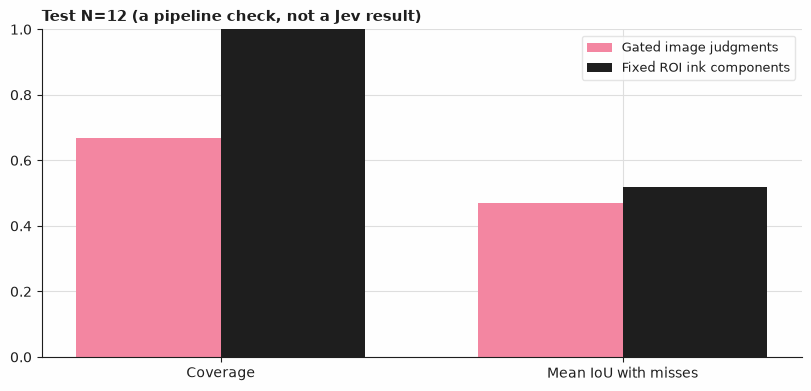

In [8]:
from matplotlib.figure import Figure

plotted = {
    name: [result["coverage"], result["mean_iou_with_misses"]] for name, result in metrics.items()
}
print(
    f"Test bar values (coverage, mean IoU including misses), N={len(test_examples)}: {plotted}{check}"
)
fig = Figure(figsize=(8, 3.8), layout="constrained")
ax = fig.subplots()
for offset, (name, values), color in zip(
    (-0.18, 0.18), plotted.items(), ("#F386A1", "#1E1E1E"), strict=True
):
    ax.bar([x + offset for x in range(2)], values, width=0.36, label=name, color=color)
ax.set_xticks([0, 1], ["Coverage", "Mean IoU with misses"])
ax.set_ylim(0, 1)
ax.set_title(f"Test N={len(test_examples)}{check}", fontsize=11)
ax.legend(loc="upper right", fontsize=9)
fig

### A confident error survives

The held-out wrong stamp crop and decorative-seal false positive are deliberately accepted by the frozen policy. Confidence is an answer field, not proof of correctness. A crop can be technically well formed while pointing to the prepared-name text or to the wrong kind of mark. Keep the failure examples when replacing synthetic answers with a recorded run.

Accepted wrong crop IDs, test N=12: ['t04', 't07'] (a pipeline check, not a Jev result)
Returned Box confidence: 0.97


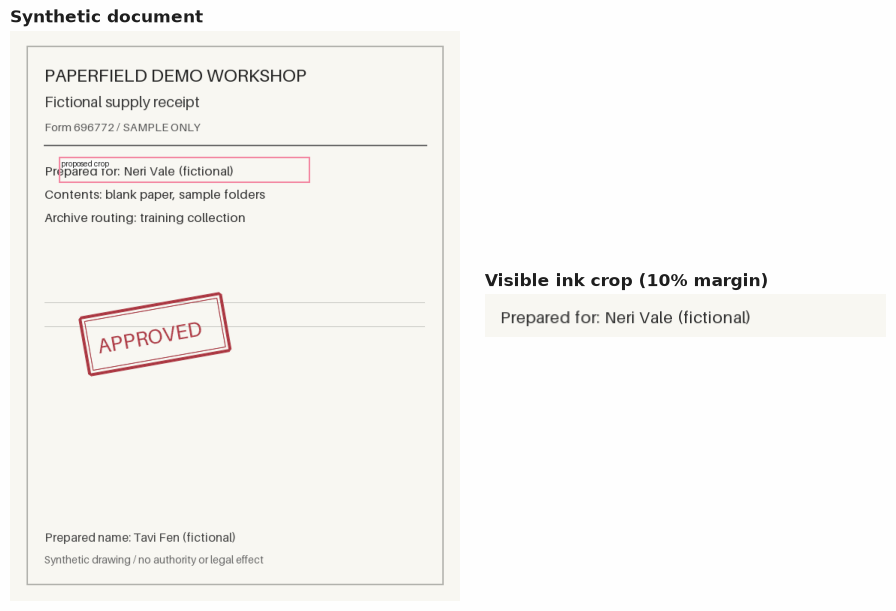

In [9]:
wrong_ids = [
    e.id
    for e in test_examples
    if test_outcomes[e.id].status == "located"
    and not helpers.resolved_correct(test_outcomes[e.id], labels[e.id])
]
print(f"Accepted wrong crop IDs, test N={len(test_examples)}: {wrong_ids}{check}")
if wrong_ids:
    wrong = next(e for e in test_examples if e.id == wrong_ids[0])
    print("Returned Box confidence:", observations[wrong.id].location.confidence)
    display(helpers.show_location(wrong.fields, root, test_outcomes[wrong.id]))
else:
    print("No accepted wrong crop in this sample.")

## What was and was not measured

The cell below prints mode, N and the actual request count. Recorded runs also identify the returned model and capture dates. Synthetic values check the gate, geometry, baseline, budget and bookkeeping; **not measured live**. No claims about Jev quality, latency, token consumption or cost follow from this run.

`run_record` preserves actual returned usage only for recorded/live answers. Unavailable fields remain `None`. Replay execution time is never reported as inference latency. This authored set is small, stylized and mostly uses colored ink; it does not measure handwriting diversity, scanner artifacts, real document populations, identity or forgery detection.

A fresh recorded experiment must choose policy on recorded validation answers and freeze it before obtaining its test answers. `helpers.record_stage` uses `(state, questions, assets)` triples with the shared recorder, then gates the dependent stage using the answers actually returned. Read the README for the capture sequence. An unrecorded live notebook run stops before aggregate evaluation.

In [10]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(
        f"N: {len(val_examples)} validation, {len(test_examples)} test, 2 unscored demos; requests={budget.used}{check}"
    )
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ())
    print(f"Provenance: {backend.mode}; returned model: {backend.model}; capture dates: {dates}")
    print(
        f"N: {len(val_examples)} validation, {len(test_examples)} test, 2 unscored demos; requests={budget.used}"
    )
accounting = [record for obs in observations.values() for record in obs.accounting]
print("First actual call accounting:", accounting[0])
print("Accounting rows:", len(accounting))

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 12 validation, 12 test, 2 unscored demos; requests=43 (a pipeline check, not a Jev result)
First actual call accounting: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}
Accounting rows: 43


## Next steps

Use [document extraction cascade](../39-document-extraction-cascade/) to study dependent questions and [confidence-gated sentiment classification](../01-sentiment-classification/) to compare a simpler gate. See [vision geometry](../../docs/vision.md) for exact pixel rounding and [live recording](../../docs/live.md) for provenance and retry budgets.

Before using a different document family, author new validation images with grayscale scans, overlapping marks and harder decorations. Freeze a policy on that validation set, then report once on a separately recorded test set. Add a second contextual check only as a new measured stage; never turn a located signature or an APPROVED-shaped stamp into a document approval.